# Notebook 2 — Baseline Multimodale

**Objectif** : Établir un score de référence rigoureux combinant texte (TF-IDF) et image (features simples)  
via un modèle LightGBM. Toutes les prédictions sortent sous forme de `predict_proba`.

**Dépendance** : `notebooks/main_notebooks/01_preprocessing_eda.ipynb` doit avoir été exécuté.

**Livrables** :
- `data/processed_clean/X_tfidf_{train,val,test}.npz` — matrices TF-IDF sparse
- `models/clean/tfidf_vectorizer.pkl` — vectorizer fité
- `models/clean/baseline_lgbm.pkl` — modèle LightGBM baseline
- `data/processed_clean/P_baseline_{train,val,test}.npy` — probabilités (27 classes)

---

## 0. Configuration

In [1]:
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
os.environ['OMP_NUM_THREADS'] = '1'

from pathlib import Path

_NB_DIR = Path('__file__').resolve().parent if '__file__' in dir() else Path.cwd()
ROOT = _NB_DIR
for _ in range(5):
    if (ROOT / 'data' / 'raw').exists():
        break
    ROOT = ROOT.parent

CFG = {
    'root':          ROOT,
    'split_dir':     ROOT / 'data' / 'split_no_crop2',
    'processed':     ROOT / 'data' / 'processed_clean',
    'images_train':  ROOT / 'data' / 'raw' / 'images' / 'image_train',
    'models_dir':    ROOT / 'models' / 'clean',
    'figures_dir':   ROOT / 'reports' / 'figures',
    # TF-IDF
    'tfidf_max_feat':  50_000,
    'tfidf_ngram':     (1, 2),
    'tfidf_min_df':    2,
    # Image features
    'img_size':        (64, 64),    # resize pour features simples
    'n_color_bins':    8,           # bins par canal pour histogramme couleur
    # LightGBM
    'lgbm_params': {
        'objective':        'multiclass',
        'num_class':        27,
        'num_leaves':       63,
        'learning_rate':    0.05,
        'n_estimators':     500,
        'subsample':        0.8,
        'colsample_bytree': 0.8,
        'class_weight':     'balanced',
        'random_state':     42,
        'n_jobs':           -1,
        'verbose':          -1,
    },
    'random_state': 42,
}

for d in ['processed', 'models_dir', 'figures_dir']:
    CFG[d].mkdir(parents=True, exist_ok=True)

print(f'ROOT : {ROOT}')

ROOT : c:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten


## 1. Imports

In [3]:
%matplotlib inline
import pickle
import logging

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

from PIL import Image

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import f1_score, classification_report
import lightgbm as lgb

logging.basicConfig(level=logging.INFO, format='%(asctime)s %(levelname)s %(message)s')
sns.set_theme(style='whitegrid')

def save_fig(name: str, dpi: int = 150):
    plt.savefig(CFG['figures_dir'] / name, dpi=dpi, bbox_inches='tight')

## 2. Chargement des splits

In [4]:
train_df = pd.read_csv(CFG['split_dir'] / 'train.csv')
val_df   = pd.read_csv(CFG['split_dir'] / 'val.csv')
test_df  = pd.read_csv(CFG['split_dir'] / 'test.csv')

y_train = np.load(CFG['processed'] / 'y_train.npy')
y_val   = np.load(CFG['processed'] / 'y_val.npy')
y_test  = np.load(CFG['processed'] / 'y_test.npy')

print(f'Train : {len(train_df):,}  Val : {len(val_df):,}  Test : {len(test_df):,}')
print(f'Colonne text_combined OK : {"text_combined" in train_df.columns}')
print(f'Colonne combined_raw OK  : {"combined_raw" in train_df.columns}')

Train : 59,441  Val : 12,737  Test : 12,738
Colonne text_combined OK : True
Colonne combined_raw OK  : True


---
## 3. Branche Texte — TF-IDF

Vectorisation TF-IDF (unigrammes + bigrammes) sur `text_combined` (texte nettoyé du Notebook 1).  
Paramètres : 50k features, sublinear_tf, min_df=2.

In [5]:
TFIDF_TRAIN_CACHE = CFG['processed'] / 'X_tfidf_train.npz'

if TFIDF_TRAIN_CACHE.exists():
    X_tfidf_train = sp.load_npz(CFG['processed'] / 'X_tfidf_train.npz')
    X_tfidf_val   = sp.load_npz(CFG['processed'] / 'X_tfidf_val.npz')
    X_tfidf_test  = sp.load_npz(CFG['processed'] / 'X_tfidf_test.npz')
    with open(CFG['models_dir'] / 'tfidf_vectorizer.pkl', 'rb') as f:
        tfidf = pickle.load(f)
    print(f'TF-IDF charge depuis cache : {X_tfidf_train.shape}')
else:
    tfidf = TfidfVectorizer(
        max_features   = CFG['tfidf_max_feat'],
        ngram_range    = CFG['tfidf_ngram'],
        sublinear_tf   = True,
        min_df         = CFG['tfidf_min_df'],
        strip_accents  = 'unicode',
    )
    X_tfidf_train = tfidf.fit_transform(train_df['text_combined'].fillna(''))
    X_tfidf_val   = tfidf.transform(val_df['text_combined'].fillna(''))
    X_tfidf_test  = tfidf.transform(test_df['text_combined'].fillna(''))

    sp.save_npz(CFG['processed'] / 'X_tfidf_train.npz', X_tfidf_train)
    sp.save_npz(CFG['processed'] / 'X_tfidf_val.npz',   X_tfidf_val)
    sp.save_npz(CFG['processed'] / 'X_tfidf_test.npz',  X_tfidf_test)
    with open(CFG['models_dir'] / 'tfidf_vectorizer.pkl', 'wb') as f:
        pickle.dump(tfidf, f)
    print(f'TF-IDF calcule et sauvegarde : {X_tfidf_train.shape}')

TF-IDF calcule et sauvegarde : (59441, 50000)


---
## 4. Branche Image — Features simples

On extrait 3 types de features images légères (pas de CNN) :
1. **Histogramme couleur** (RGB, 8 bins/canal → 192 features)
2. **Features texturales** (variance Laplacien, ratio fond blanc)
3. **Features produit** (zoom_ratio, blur_score, has_desc)

In [6]:
def extract_color_histogram(image_path: Path, n_bins: int = 8) -> np.ndarray:
    """Histogramme couleur RGB normalisé (n_bins^3 features) -> aplatissement en vecteur."""
    try:
        img = np.array(Image.open(image_path).convert('RGB').resize(CFG['img_size']))
        # Histogramme 3D
        hist, _ = np.histogramdd(
            img.reshape(-1, 3).astype(float),
            bins=n_bins,
            range=[(0, 256), (0, 256), (0, 256)]
        )
        hist = hist.flatten().astype(np.float32)
        hist /= (hist.sum() + 1e-9)
        return hist
    except Exception:
        return np.zeros(n_bins ** 3, dtype=np.float32)


def extract_image_features(row: pd.Series, img_dir: Path) -> np.ndarray:
    """
    Combine histogramme couleur + features produit numeriques.
    Vecteur final : (n_bins^3 + 2) features
    """
    path = img_dir / str(row['image_name'])
    hist = extract_color_histogram(path, CFG['n_color_bins'])
    extra = np.array([
        float(row.get('zoom_ratio', 1.0)),
        float(row.get('blur_score', 0.0)),
    ], dtype=np.float32)
    return np.concatenate([hist, extra])

print(f'Dimension features image par produit : {CFG["n_color_bins"]**3 + 2}')

Dimension features image par produit : 514


In [7]:
IMG_FEAT_TRAIN_CACHE = CFG['processed'] / 'X_img_simple_train.npy'

if IMG_FEAT_TRAIN_CACHE.exists():
    X_img_train = np.load(CFG['processed'] / 'X_img_simple_train.npy')
    X_img_val   = np.load(CFG['processed'] / 'X_img_simple_val.npy')
    X_img_test  = np.load(CFG['processed'] / 'X_img_simple_test.npy')
    print(f'Image features chargees depuis cache : {X_img_train.shape}')
else:
    print('Extraction features images...')
    img_dir = CFG['split_dir'] / 'train'
    X_img_train = np.stack([
        extract_image_features(row, CFG['split_dir'] / 'train')
        for _, row in tqdm(train_df.iterrows(), total=len(train_df), desc='Train')
    ])
    X_img_val = np.stack([
        extract_image_features(row, CFG['split_dir'] / 'val')
        for _, row in tqdm(val_df.iterrows(), total=len(val_df), desc='Val')
    ])
    X_img_test = np.stack([
        extract_image_features(row, CFG['split_dir'] / 'test')
        for _, row in tqdm(test_df.iterrows(), total=len(test_df), desc='Test')
    ])
    np.save(CFG['processed'] / 'X_img_simple_train.npy', X_img_train)
    np.save(CFG['processed'] / 'X_img_simple_val.npy',   X_img_val)
    np.save(CFG['processed'] / 'X_img_simple_test.npy',  X_img_test)
    print(f'Sauvegarde : {X_img_train.shape}')

Extraction features images...


Test: 100%|██████████| 12738/12738 [01:35<00:00, 133.58it/s]


Sauvegarde : (59441, 514)


## 5. Features additionnelles construites

- **Language OHE** : encodage one-hot de la langue détectée
- **Metadata** : has_desc, len_desig, len_desc normalisés

In [8]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Encodage langue
ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
lang_train = ohe.fit_transform(train_df[['language']].fillna('unknown'))
lang_val   = ohe.transform(val_df[['language']].fillna('unknown'))
lang_test  = ohe.transform(test_df[['language']].fillna('unknown'))

# Features numeriques
NUMERIC_COLS = ['len_desig', 'len_desc', 'has_desc', 'zoom_ratio']
scaler = StandardScaler()
num_train = scaler.fit_transform(train_df[NUMERIC_COLS].fillna(0))
num_val   = scaler.transform(val_df[NUMERIC_COLS].fillna(0))
num_test  = scaler.transform(test_df[NUMERIC_COLS].fillna(0))

# Concatenation features construites (dense)
X_extra_train = np.hstack([lang_train, num_train])
X_extra_val   = np.hstack([lang_val, num_val])
X_extra_test  = np.hstack([lang_test, num_test])

np.save(CFG['processed'] / 'X_extra_train.npy', X_extra_train)
np.save(CFG['processed'] / 'X_extra_val.npy',   X_extra_val)
np.save(CFG['processed'] / 'X_extra_test.npy',  X_extra_test)

print(f'X_extra shape : {X_extra_train.shape}')

X_extra shape : (59441, 8)


---
## 6. Assemblage et entraînement LightGBM Baseline

La feature matrix finale combine :
- TF-IDF sparse (50k)  
- Histogramme couleur + extras image (514)  
- Language OHE + méta numériques (4+n)

In [9]:
# Assemblage : TF-IDF (sparse) + dense features
def assemble_features(tfidf_mat, img_mat, extra_mat):
    dense_combined = np.hstack([img_mat, extra_mat])
    return sp.hstack([tfidf_mat, sp.csr_matrix(dense_combined)], format='csr')

X_train_full = assemble_features(X_tfidf_train, X_img_train, X_extra_train)
X_val_full   = assemble_features(X_tfidf_val,   X_img_val,   X_extra_val)
X_test_full  = assemble_features(X_tfidf_test,  X_img_test,  X_extra_test)

print(f'Shape finale : train={X_train_full.shape}  val={X_val_full.shape}')

Shape finale : train=(59441, 50522)  val=(12737, 50522)


In [10]:
BASELINE_MODEL_PATH = CFG['models_dir'] / 'baseline_lgbm.pkl'

if BASELINE_MODEL_PATH.exists():
    with open(BASELINE_MODEL_PATH, 'rb') as f:
        clf_baseline = pickle.load(f)
    print('Modele baseline charge depuis cache.')
else:
    print('Entrainement LightGBM baseline...')
    clf_baseline = lgb.LGBMClassifier(**CFG['lgbm_params'])
    clf_baseline.fit(
        X_train_full, y_train,
        eval_set=[(X_val_full, y_val)],
        callbacks=[lgb.early_stopping(50, verbose=False),
                   lgb.log_evaluation(period=50)],
    )
    with open(BASELINE_MODEL_PATH, 'wb') as f:
        pickle.dump(clf_baseline, f)
    print(f'Modele sauvegarde : {BASELINE_MODEL_PATH}')

Entrainement LightGBM baseline...
[50]	valid_0's multi_logloss: 0.741925
[100]	valid_0's multi_logloss: 0.613455
[150]	valid_0's multi_logloss: 0.58895
[200]	valid_0's multi_logloss: 0.595061
Modele sauvegarde : c:\Users\veyss\Nouveau dossier\nov25_alt1_mle_rakuten\models\clean\baseline_lgbm.pkl


In [11]:
# Evaluation
y_pred_val  = clf_baseline.predict(X_val_full)
y_pred_test = clf_baseline.predict(X_test_full)

f1_val  = f1_score(y_val, y_pred_val, average='weighted')
f1_test = f1_score(y_test, y_pred_test, average='weighted')

print(f'F1 weighted  Val  : {f1_val:.4f}')
print(f'F1 weighted  Test : {f1_test:.4f}')

# Export probabilites
P_baseline_train = clf_baseline.predict_proba(X_train_full)
P_baseline_val   = clf_baseline.predict_proba(X_val_full)
P_baseline_test  = clf_baseline.predict_proba(X_test_full)

np.save(CFG['processed'] / 'P_baseline_train.npy', P_baseline_train)
np.save(CFG['processed'] / 'P_baseline_val.npy',   P_baseline_val)
np.save(CFG['processed'] / 'P_baseline_test.npy',  P_baseline_test)

print(f'\nProbabilites sauvegardees : shape={P_baseline_train.shape}')

c:\Users\veyss\anaconda3\envs\rakuten_env\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
c:\Users\veyss\anaconda3\envs\rakuten_env\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


F1 weighted  Val  : 0.8262
F1 weighted  Test : 0.8321


c:\Users\veyss\anaconda3\envs\rakuten_env\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



Probabilites sauvegardees : shape=(59441, 27)


---
## 7. Analyse des résultats Baseline

### 7.1 Matrice de confusion

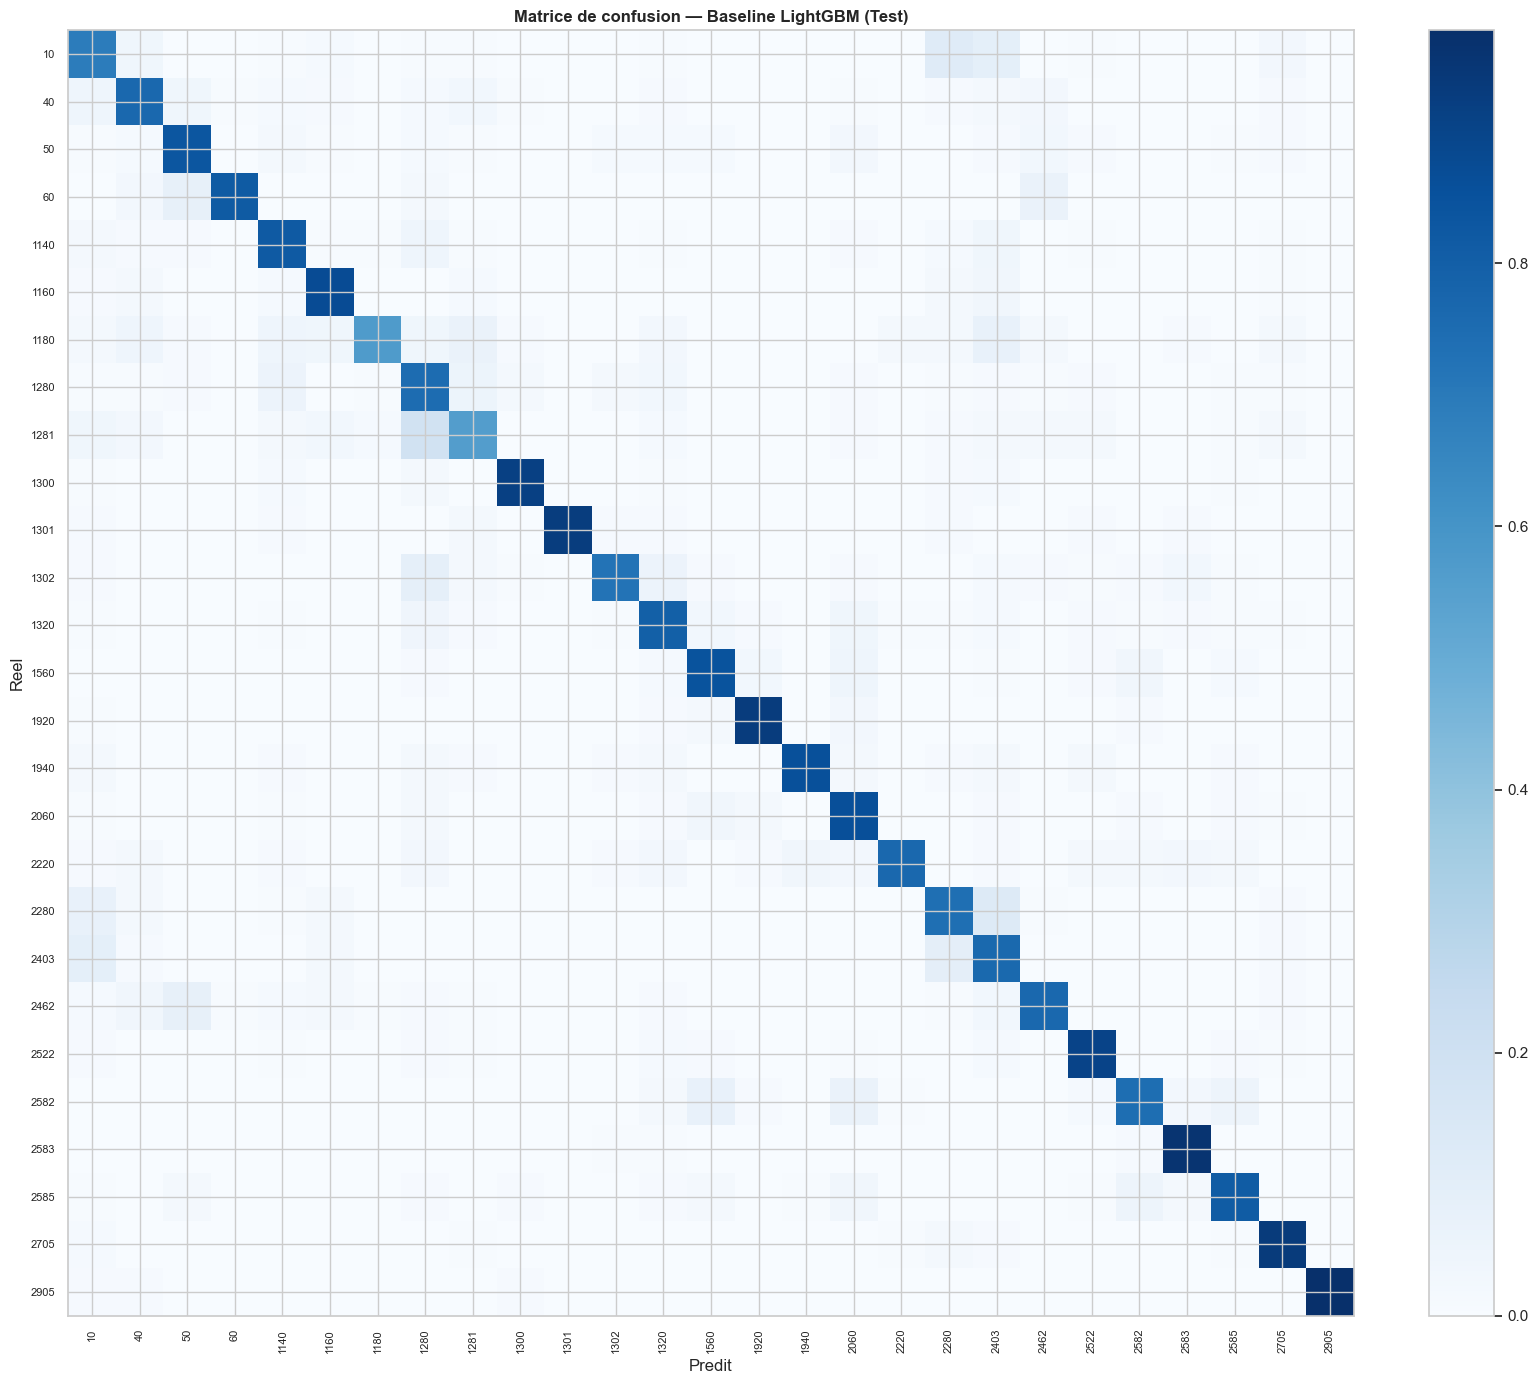

In [12]:
from sklearn.metrics import confusion_matrix
import pickle

with open(CFG['models_dir'] / 'label_encoder.pkl', 'rb') as f:
    le = pickle.load(f)

cm = confusion_matrix(y_test, y_pred_test)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(16, 14))
im = ax.imshow(cm_norm, interpolation='nearest', cmap='Blues')
plt.colorbar(im, ax=ax, fraction=0.046)
class_labels = [str(c) for c in le.classes_]
ax.set_xticks(range(len(class_labels)))
ax.set_yticks(range(len(class_labels)))
ax.set_xticklabels(class_labels, rotation=90, fontsize=8)
ax.set_yticklabels(class_labels, fontsize=8)
ax.set_xlabel('Predit')
ax.set_ylabel('Reel')
ax.set_title('Matrice de confusion — Baseline LightGBM (Test)', fontweight='bold')
plt.tight_layout()
save_fig('baseline_confusion_matrix.png')
plt.show()

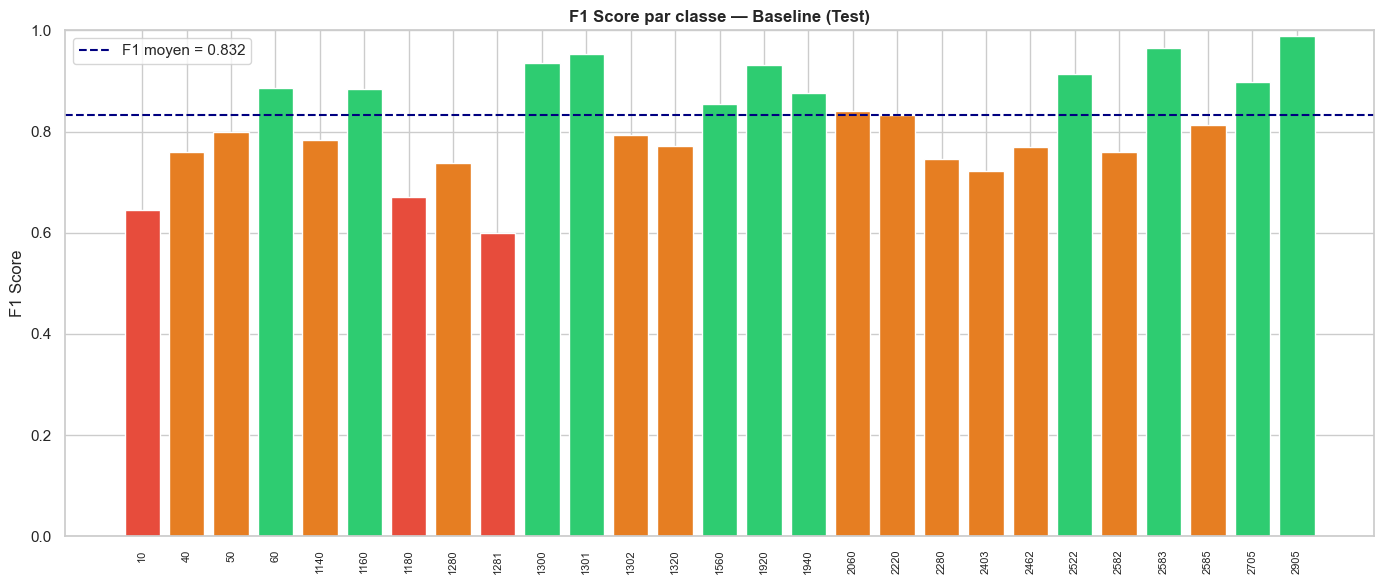


Classes les plus difficiles :
  prdtypecode=1281 : F1=0.600
  prdtypecode=10 : F1=0.645
  prdtypecode=1180 : F1=0.670
  prdtypecode=2403 : F1=0.722
  prdtypecode=1280 : F1=0.738


In [13]:
# F1 par classe
f1_per_class = f1_score(y_test, y_pred_test, average=None)

fig, ax = plt.subplots(figsize=(14, 6))
colors = ['#e74c3c' if v < 0.7 else '#e67e22' if v < 0.85 else '#2ecc71' for v in f1_per_class]
ax.bar(range(len(f1_per_class)), f1_per_class, color=colors)
ax.axhline(f1_test, color='navy', linestyle='--', label=f'F1 moyen = {f1_test:.3f}')
ax.set_xticks(range(len(f1_per_class)))
ax.set_xticklabels(le.classes_, rotation=90, fontsize=8)
ax.set_ylabel('F1 Score')
ax.set_ylim(0, 1)
ax.set_title('F1 Score par classe — Baseline (Test)', fontweight='bold')
ax.legend()
plt.tight_layout()
save_fig('baseline_f1_per_class.png')
plt.show()

print('\nClasses les plus difficiles :')
hard_classes = sorted(enumerate(f1_per_class), key=lambda x: x[1])[:5]
for idx, score in hard_classes:
    print(f'  prdtypecode={le.classes_[idx]} : F1={score:.3f}')

### 7.2 Importance des features TF-IDF

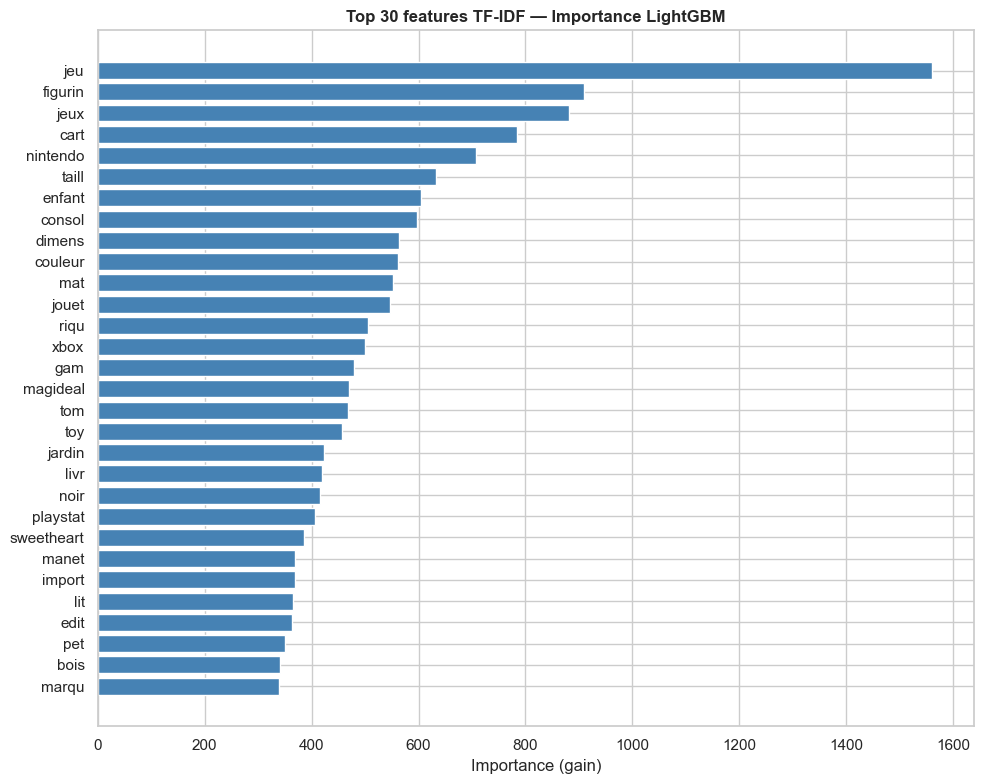

In [14]:
# Top 30 features les plus importantes (indices TF-IDF)
importances = clf_baseline.feature_importances_
tfidf_importances = importances[:CFG['tfidf_max_feat']]
feature_names = np.array(tfidf.get_feature_names_out())

top30_idx = np.argsort(tfidf_importances)[-30:]
top30_names = feature_names[top30_idx]
top30_scores = tfidf_importances[top30_idx]

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(top30_names, top30_scores, color='steelblue')
ax.set_title('Top 30 features TF-IDF — Importance LightGBM', fontweight='bold')
ax.set_xlabel('Importance (gain)')
plt.tight_layout()
save_fig('baseline_tfidf_importance.png')
plt.show()

---
## 8. Récapitulatif Baseline

In [15]:
print('=' * 60)
print('  NOTEBOOK 2 — BILAN BASELINE MULTIMODALE')
print('=' * 60)
print()
print(f'  F1 weighted (Val)  : {f1_val:.4f}')
print(f'  F1 weighted (Test) : {f1_test:.4f}')
print()
print('FEATURES')
print(f'  TF-IDF      : {X_tfidf_train.shape[1]:,} features (1-2 grams, sublinear_tf)')
print(f'  Image hist  : {X_img_train.shape[1]:,} features (couleur + zoom + blur)')
print(f'  Extra       : {X_extra_train.shape[1]:,} features (langue OHE + numeriques)')
print(f'  TOTAL       : {X_train_full.shape[1]:,} features')
print()
print('FICHIERS GENERES')
for p in [
    CFG['processed'] / 'X_tfidf_train.npz',
    CFG['models_dir'] / 'tfidf_vectorizer.pkl',
    CFG['models_dir'] / 'baseline_lgbm.pkl',
    CFG['processed'] / 'P_baseline_train.npy',
    CFG['processed'] / 'P_baseline_val.npy',
    CFG['processed'] / 'P_baseline_test.npy',
]:
    print(f'  [{"OK" if p.exists() else "MANQUANT"}] {p.relative_to(ROOT)}')
print()
print('PROCHAIN NOTEBOOK : 03_experiments_texte.ipynb')

  NOTEBOOK 2 — BILAN BASELINE MULTIMODALE

  F1 weighted (Val)  : 0.8262
  F1 weighted (Test) : 0.8321

FEATURES
  TF-IDF      : 50,000 features (1-2 grams, sublinear_tf)
  Image hist  : 514 features (couleur + zoom + blur)
  Extra       : 8 features (langue OHE + numeriques)
  TOTAL       : 50,522 features

FICHIERS GENERES
  [OK] data\processed_clean\X_tfidf_train.npz
  [OK] models\clean\tfidf_vectorizer.pkl
  [OK] models\clean\baseline_lgbm.pkl
  [OK] data\processed_clean\P_baseline_train.npy
  [OK] data\processed_clean\P_baseline_val.npy
  [OK] data\processed_clean\P_baseline_test.npy

PROCHAIN NOTEBOOK : 03_experiments_texte.ipynb
